# Configurable Abu Dhabi autonomy planning

This notebook sizes discrete solar and battery equipment for a configurable islanded period. The default question is:

`P(total unmet energy during a 24-hour horizon > 0.1 kWh) <= 5%`

The default site is Abu Dhabi city centre (`24.4539, 54.3773`, `Asia/Dubai`). Every episode starts from the configured battery state of charge; there is no controller or state-of-charge burn-in. Training, validation, and final-test simulations use independent seeds and manifests.

## What the result means

This is an autonomy-planning study, not an absolute blackout guarantee. A recommendation is released only if held-out calibration, native-SPFlow/MIO parity, and a one-sided held-out 95% risk bound all pass. Otherwise the HiGHS result is still shown, but it is labeled **exploratory**.

PVGIS TMY describes typical meteorology rather than interannual extremes. The default synthetic small-commercial demand is illustrative and not calibrated to an Abu Dhabi site. A decision-grade run needs aligned measured site demand.

In [1]:
from dataclasses import replace
from html import escape
from pathlib import Path

import pandas as pd

from open_energy_lab.demand import (
    SyntheticCommercialDemandConfig, build_measured_demand_training_payload,
    build_synthetic_demand_training_payload, fit_demand_model,
)
from open_energy_lab.planning import (
    AdequacyEventDefinition, BatteryDesignOption, GridAvailabilityPolicy,
    PlanningStudyRequest, SPNCandidateScore, SolarDesignOption,
    assess_calibration, assess_recommendation, brier_score_by_configuration,
    compile_planning_study_tpm, fit_planning_study_tpm, iter_study_rows,
    select_spn_candidate, solve_planning_study,
)
from open_energy_lab.simulator import (
    ArbitrageObjectiveRepresentation, BatteryComponent, BatteryLoadPVScenario,
    DispatchRequestSeries, LoadComponent, PVComponent, PriceSignal,
    generate_planning_study_dataset,
)
from open_energy_lab.simulator.demand import CoolingServiceConfiguration, LocalElectricCoolingConfiguration
from open_energy_lab.simulator.weather import weather_component_from_sampled_trace
from open_energy_lab.tpm import TPMFitConfig, TPMQueryRequest, query_tpm_artifact
from open_energy_lab.weather import (
    PVGISTMYRequestConfig, WeatherSamplingRequest, fit_weather_dataset,
    load_or_fetch_tmy_dataset, load_weather_artifact, sample_weather_family,
)

## 1. Study configuration

Change this cell to study a different location, start hour, horizon, demand source, grid policy, equipment catalog, cost basis, event, probability limit, sample budget, or SPN structure settings. The PVGIS endpoint is deliberately versioned to 5.3. A missing cache plus an unavailable/disabled network is a hard error; no fixture is substituted.

In [2]:
REPO_ROOT = Path.cwd()
OUTPUT_ROOT = REPO_ROOT / "tmp/abu-dhabi-autonomy-study"
CACHE_ROOT = OUTPUT_ROOT / "cache"
LOCATION = {"name": "Abu Dhabi city centre", "latitude": 24.4539, "longitude": 54.3773, "timezone": "Asia/Dubai"}
WEATHER_API = PVGISTMYRequestConfig(endpoint_url="https://re.jrc.ec.europa.eu/api/v5_3/", use_horizon=True, start_year=None, end_year=None, timeout_seconds=30)
ALLOW_NETWORK = True
REFRESH_WEATHER_CACHE = False
HORIZON_STEPS = 24
LOCAL_START_STEP = 0
TIMESTEP_HOURS = 1.0
INITIAL_SOC = 1.0
MINIMUM_SOC = 0.10
CHARGE_EFFICIENCY = 0.95
DISCHARGE_EFFICIENCY = 0.95
DEMAND_MODE = "synthetic"  # "synthetic" or "measured_csv"
MEASURED_DEMAND_CSV = REPO_ROOT / "data/abu_dhabi_measured_demand.csv"
SYNTHETIC_DEMAND = SyntheticCommercialDemandConfig(random_seed=20260820, electric_kw_per_rt=1.15)
SOLAR_CAPACITIES_KW = (80.0, 120.0, 160.0)
BATTERY_CAPACITIES_KWH = (100.0, 200.0, 300.0)
BATTERY_C_RATE = 0.5
SOLAR_COST_AED_PER_KW = 3_000.0
BATTERY_COST_AED_PER_KWH = 1_200.0
GRID_MODE = "islanded"  # "islanded" or "markov"
MARKOV_OUTAGE_START_PROBABILITY = 0.02
MARKOV_RECOVERY_PROBABILITY = 0.30
EVENT_KIND = "unmet_energy_kwh"
EVENT_THRESHOLD = 0.1
CHANCE_LIMIT = 0.05
SAMPLE_COUNTS = {"train": 1_000, "validation": 250, "test": 250}
SPLIT_SEEDS = {"train": 13, "validation": 37, "test": 101}
BATCH_SIZE = 100
WORKER_COUNT = 1
SHARD_FORMAT = "parquet"
SPN_CANDIDATES = {"default": {}, "finer": {"min_instances_slice": 100, "threshold": 0.15}, "coarser": {"min_instances_slice": 1_000, "threshold": 0.50}}
MEAN_CALIBRATION_ERROR_LIMIT = 0.05
MAX_CALIBRATION_ERROR_LIMIT = 0.10
NATIVE_MIO_TOLERANCE = 1e-6
MAX_TENSOR_BYTES = 512 * 1024 * 1024

## 2. Fetch or load the canonical PVGIS TMY, then fit once

The canonical hourly table and fitted weather artifact are separate cached products. `fit_weather_dataset` consumes the already fetched table, so a fresh run performs at most one live request. PVGIS 5.3 is used because that API generation includes the relevant TMY timestamp corrections for regions including the Middle East. See the [PVGIS API documentation](https://joint-research-centre.ec.europa.eu/photovoltaic-geographical-information-system/pvgis/using-pvgis-5/api-non-interactive-service_en) and [TMY documentation](https://joint-research-centre.ec.europa.eu/photovoltaic-geographical-information-system/pvgis/using-pvgis-5/pvgis-5-tools/pvgis-typical-meteorological-year-tmy-generator_en).

In [3]:
canonical_weather_path = CACHE_ROOT / "abu-dhabi-pvgis-5.3-tmy-canonical.json"
weather_artifact_path = CACHE_ROOT / "abu-dhabi-pvgis-5.3-weather-artifact.json"
canonical_weather = load_or_fetch_tmy_dataset(LOCATION["latitude"], LOCATION["longitude"], timezone_name=LOCATION["timezone"], cache_path=canonical_weather_path, api_config=WEATHER_API, allow_network=ALLOW_NETWORK, refresh_cache=REFRESH_WEATHER_CACHE)
if len(canonical_weather.timestamp_utc) != 8_760:
    raise ValueError(f"expected one 8,760-record hourly TMY; received {len(canonical_weather.timestamp_utc):,}")
if weather_artifact_path.exists():
    weather_artifact = load_weather_artifact(weather_artifact_path, expected_timestep_hours=TIMESTEP_HOURS)
    if weather_artifact.training_record_summary["dataset_id"] != canonical_weather.dataset_id:
        weather_artifact = fit_weather_dataset(canonical_weather, output_path=weather_artifact_path)
else:
    weather_artifact = fit_weather_dataset(canonical_weather, output_path=weather_artifact_path)
print("Canonical records:", f"{len(canonical_weather.timestamp_utc):,}")
print("Canonical cache:  ", canonical_weather.source_metadata["cache_provenance"])
print("Weather artifact:", weather_artifact_path)
print("PVGIS request:   ", canonical_weather.source_metadata.get("pvgis_request", WEATHER_API.to_dict()))

Canonical records: 8,760
Canonical cache:   {'status': 'miss_fetched', 'path': '/home/nicolas.avila/dev/open-energy-lab/tmp/abu-dhabi-autonomy-study/cache/abu-dhabi-pvgis-5.3-tmy-canonical.json', 'payload_sha256': '7b0559294c172bf14893675622c200b9306f7939b018a1a31b2336bcc058a302', 'schema_version': 'v1'}
Weather artifact: /home/nicolas.avila/dev/open-energy-lab/tmp/abu-dhabi-autonomy-study/cache/abu-dhabi-pvgis-5.3-weather-artifact.json
PVGIS request:    {'endpoint_url': 'https://re.jrc.ec.europa.eu/api/v5_3/', 'use_horizon': True, 'start_year': None, 'end_year': None, 'timeout_seconds': 30, 'map_variables': True}


In [4]:
class InlineSVG:
    def __init__(self, source): self.source = source
    def _repr_svg_(self): return self.source
VISUALIZATION_ROOT = OUTPUT_ROOT / "visualizations"
VISUALIZATION_ROOT.mkdir(parents=True, exist_ok=True)
def save_svg(filename, chart):
    path = VISUALIZATION_ROOT / filename; path.write_text(chart.source, encoding="utf-8"); print("Saved", path); return chart
def line_chart(title, series, y_label, width=760, height=360):
    left, right, top, bottom = 75, 25, 55, 55; plot_w, plot_h = width-left-right, height-top-bottom
    all_values = [float(v) for values, _ in series.values() for v in values]; y_min, y_max = min(all_values), max(all_values)
    if y_min == y_max: y_max = y_min + 1.0
    n = max(len(values) for values, _ in series.values()); x = lambda i: left + plot_w*i/max(1, n-1); y = lambda v: top + plot_h*(y_max-float(v))/(y_max-y_min)
    parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}">', '<rect width="100%" height="100%" fill="#fbfcfe"/>', f'<text x="{width/2}" y="27" text-anchor="middle" font-size="18" font-weight="600">{escape(title)}</text>']
    for tick in range(5):
        value = y_min + (y_max-y_min)*tick/4; yp = y(value); parts += [f'<line x1="{left}" y1="{yp}" x2="{width-right}" y2="{yp}" stroke="#dce2ea"/>', f'<text x="{left-9}" y="{yp+4}" text-anchor="end" font-size="10">{value:.1f}</text>']
    for index, (name, (values, color)) in enumerate(series.items()):
        points = ' '.join(f'{x(i):.1f},{y(v):.1f}' for i, v in enumerate(values)); parts += [f'<polyline points="{points}" fill="none" stroke="{color}" stroke-width="2.5"/>', f'<text x="{left+index*165}" y="45" font-size="11" fill="{color}">{escape(name)}</text>']
    parts += [f'<text x="18" y="{height/2}" transform="rotate(-90 18 {height/2})" text-anchor="middle" font-size="11">{escape(y_label)}</text>', '</svg>']; return InlineSVG(''.join(parts))
def heatmap_chart(title, frame, value_column, row_column="battery_capacity_kwh", col_column="solar_capacity_kw"):
    rows, cols = sorted(frame[row_column].unique()), sorted(frame[col_column].unique()); width, height, left, top, cell_w, cell_h = 720, 390, 170, 80, 165, 82
    parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}">', '<rect width="100%" height="100%" fill="#fbfcfe"/>', f'<text x="{width/2}" y="28" text-anchor="middle" font-size="18" font-weight="600">{escape(title)}</text>']
    for ci, col in enumerate(cols): parts.append(f'<text x="{left+ci*cell_w+75}" y="60" text-anchor="middle" font-size="12">{col:g} kW solar</text>')
    for ri, row in enumerate(rows):
        parts.append(f'<text x="{left-12}" y="{top+ri*cell_h+40}" text-anchor="end" font-size="12">{row:g} kWh battery</text>')
        for ci, col in enumerate(cols):
            value = float(frame.loc[(frame[row_column] == row) & (frame[col_column] == col), value_column].iloc[0]); clipped=max(0,min(1,value)); color=f'#{round(50+190*clipped):02x}{round(175-105*clipped):02x}55'; xp,yp=left+ci*cell_w,top+ri*cell_h
            parts += [f'<rect x="{xp}" y="{yp}" width="150" height="70" rx="7" fill="{color}"/>', f'<text x="{xp+75}" y="{yp+42}" text-anchor="middle" font-size="20" fill="white" font-weight="700">{value:.1%}</text>']
    parts.append('</svg>'); return InlineSVG(''.join(parts))

### Representative TMY days and hourly weather distributions

Saved /home/nicolas.avila/dev/open-energy-lab/tmp/abu-dhabi-autonomy-study/visualizations/representative-tmy-temperature.svg
Saved /home/nicolas.avila/dev/open-energy-lab/tmp/abu-dhabi-autonomy-study/visualizations/hourly-weather-distribution.svg


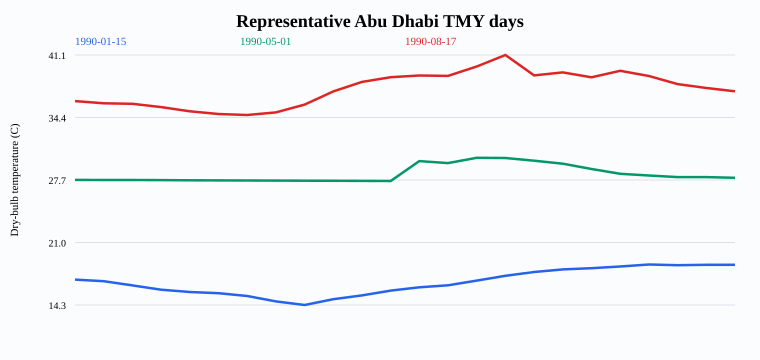

In [5]:
weather_frame = pd.DataFrame({name: canonical_weather.field_series[name] for name in canonical_weather.canonical_field_order[1:]})
weather_frame["local_timestamp"] = pd.to_datetime(canonical_weather.local_civil_step_labels); weather_frame["local_date"] = weather_frame["local_timestamp"].dt.date; weather_frame["local_hour"] = weather_frame["local_timestamp"].dt.hour
daily_temperature = weather_frame.groupby("local_date")["dry_bulb_air_temperature_c"].mean().sort_values(); representative_dates = [daily_temperature.index[0], daily_temperature.index[len(daily_temperature)//2], daily_temperature.index[-1]]
representative_series = {str(date): (weather_frame.loc[weather_frame["local_date"] == date, "dry_bulb_air_temperature_c"].tolist(), color) for date, color in zip(representative_dates, ("#2563eb", "#059669", "#dc2626"))}
representative_weather_chart = save_svg("representative-tmy-temperature.svg", line_chart("Representative Abu Dhabi TMY days", representative_series, "Dry-bulb temperature (C)"))
hourly = weather_frame.groupby("local_hour")["global_horizontal_irradiance_w_per_m2"].quantile([0.1, 0.5, 0.9]).unstack()
hourly_distribution_chart = save_svg("hourly-weather-distribution.svg", line_chart("Hourly TMY GHI distribution", {"p10": (hourly[0.1], "#93c5fd"), "median": (hourly[0.5], "#2563eb"), "p90": (hourly[0.9], "#1e3a8a")}, "GHI (W/m2)"))
representative_weather_chart

## 3. Prepare and fit demand

`synthetic` generates a labeled, reproducible small-commercial history from the TMY: roughly 12–30 kW non-cooling baseline, occupancy/temperature/humidity cooling, and correlated Gaussian residuals. `measured_csv` requires at least 90 complete hourly days and separate non-cooling electricity and cooling RT columns. Total electricity without separate cooling is rejected to prevent double counting. Both modes pass through `fit_demand_model`.

In [6]:
if DEMAND_MODE == "synthetic":
    demand_training_payload = build_synthetic_demand_training_payload(canonical_weather, config=SYNTHETIC_DEMAND)
elif DEMAND_MODE == "measured_csv":
    demand_training_payload = build_measured_demand_training_payload(MEASURED_DEMAND_CSV, timezone_name=LOCATION["timezone"])
else:
    raise ValueError("DEMAND_MODE must be 'synthetic' or 'measured_csv'")
demand_artifact_path = CACHE_ROOT / f"demand-{DEMAND_MODE}-artifact.json"; demand_artifact_path.parent.mkdir(parents=True, exist_ok=True)
demand_artifact = fit_demand_model(demand_training_payload, output_path=demand_artifact_path)
training_total_kw = pd.Series(demand_training_payload["non_thermal_electric_demand_kw"]) + 1.15 * pd.Series(demand_training_payload["cooling_demand_rt"])
print("Demand mode:       ", DEMAND_MODE); print("Demand provenance: ", demand_training_payload["provenance"]); print("Training peak:      ", f"{training_total_kw.max():.1f} kW"); print("Demand artifact:    ", demand_artifact_path)

Demand mode:        synthetic
Demand provenance:  {'demand_source_mode': 'synthetic', 'profile_label': 'illustrative_small_commercial', 'site_calibration_status': 'not_site_calibrated', 'weather_dataset_id': 'pvgis-tmy:524fe0db068b', 'generator_configuration': {'random_seed': 20260820, 'non_cooling_min_kw': 12.0, 'non_cooling_max_kw': 30.0, 'cooling_balance_temperature_c': 24.0, 'cooling_electric_cap_kw': 38.0, 'electric_kw_per_rt': 1.15, 'non_cooling_residual_sigma_kw': 1.2, 'cooling_residual_sigma_kw': 2.0, 'residual_correlation': 0.65, 'residual_autocorrelation': 0.7}, 'cooling_conversion_electric_kw_per_rt': 1.15, 'notes': ['occupancy_temperature_humidity_cooling_interaction', 'correlated_gaussian_autoregressive_residuals', 'not_decision_grade_without_aligned_measured_site_demand']}
Training peak:       68.9 kW
Demand artifact:     /home/nicolas.avila/dev/open-energy-lab/tmp/abu-dhabi-autonomy-study/cache/demand-synthetic-artifact.json


Saved /home/nicolas.avila/dev/open-energy-lab/tmp/abu-dhabi-autonomy-study/visualizations/fitted-versus-input-demand.svg


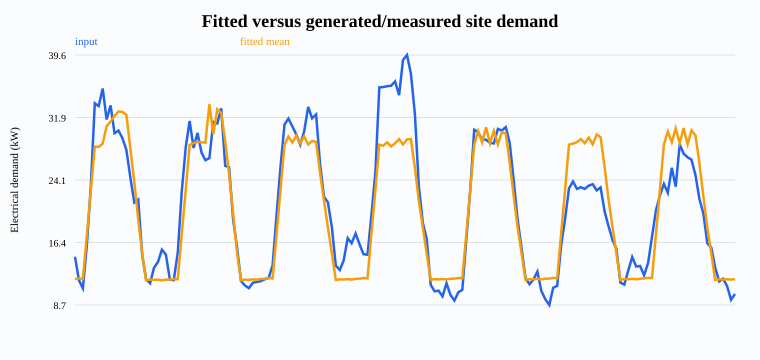

In [9]:
required_weather = demand_artifact.required_weather_field_order
def fitted_demand_value(model, baseline_name, index):
    local_hour = pd.Timestamp(demand_training_payload["local_civil_step_labels"][index]).hour
    return max(0.0, float(model[baseline_name][local_hour]) + sum(float(model["weather_response_terms"][name]) * float(demand_training_payload["weather_field_series"][name][index]) for name in required_weather))
plot_steps = min(7*24, len(training_total_kw))
fitted_total_kw = [fitted_demand_value(demand_artifact.non_thermal_electric_model, "local_step_baseline_kw", i) + 1.15*fitted_demand_value(demand_artifact.cooling_demand_model, "local_step_baseline_rt", i) for i in range(plot_steps)]
demand_fit_chart = save_svg("fitted-versus-input-demand.svg", line_chart("Fitted versus generated/measured site demand", {"input": (training_total_kw.iloc[:plot_steps], "#2563eb"), "fitted mean": (fitted_total_kw, "#f59e0b")}, "Electrical demand (kW)")); demand_fit_chart

## 4. Build the physical scenario and 3 x 3 equipment grid

Storage power is 0.5C. Every option explicitly sets 100% initial SOC, 10% minimum SOC, and 95% charge/discharge efficiency. Each independently simulated episode starts at that SOC; sampled history before `LOCAL_START_STEP` is not dispatched through the battery.

In [10]:
battery_options = tuple(BatteryDesignOption(f"battery-{capacity:g}", capacity, BATTERY_C_RATE*capacity, BATTERY_C_RATE*capacity, BATTERY_COST_AED_PER_KWH*capacity, charge_efficiency=CHARGE_EFFICIENCY, discharge_efficiency=DISCHARGE_EFFICIENCY, initial_soc=INITIAL_SOC, min_soc=MINIMUM_SOC, max_soc=1.0) for capacity in BATTERY_CAPACITIES_KWH)
solar_options = tuple(SolarDesignOption(f"solar-{capacity:g}", capacity, SOLAR_COST_AED_PER_KW*capacity) for capacity in SOLAR_CAPACITIES_KW)
base_weather_family = sample_weather_family(weather_artifact, request=WeatherSamplingRequest(num_steps=HORIZON_STEPS, scenario_count=1, family_seed=13, local_start_step=LOCAL_START_STEP), expected_timestep_hours=TIMESTEP_HOURS)
weather_component = weather_component_from_sampled_trace(base_weather_family.sampled_traces[0]); time_grid = weather_component.time_grid
base_scenario = BatteryLoadPVScenario(scenario_id="abu-dhabi-autonomy-template", time_grid=time_grid, battery=BatteryComponent(name="battery", capacity_kwh=BATTERY_CAPACITIES_KWH[0], max_charge_kw=BATTERY_C_RATE*BATTERY_CAPACITIES_KWH[0], max_discharge_kw=BATTERY_C_RATE*BATTERY_CAPACITIES_KWH[0], charge_efficiency=CHARGE_EFFICIENCY, discharge_efficiency=DISCHARGE_EFFICIENCY, initial_soc=INITIAL_SOC, min_soc=MINIMUM_SOC), load=LoadComponent(name="placeholder-load", demand_kw=[0.0]*HORIZON_STEPS, interpretation="exogenous-consumption", time_grid=time_grid, source=f"{DEMAND_MODE}-demand-artifact"), weather=weather_component, pv=PVComponent(name="pv", rated_power_kw=SOLAR_CAPACITIES_KW[0], temperature_coefficient_pct_per_c=-0.4, reference_irradiance_w_per_m2=1000.0, reference_temperature_c=25.0, derivation_name="ghi-linear-temperature-adjusted", irradiance_field_names=("global_horizontal_irradiance_w_per_m2",)), price_signal=PriceSignal(currency="AED", unit_rate_name="planning-placeholder", import_prices=[0.0]*HORIZON_STEPS, export_price_ratio=0.0, interpretation="islanded planning placeholder", time_alignment="step-start", time_grid=time_grid), objective=ArbitrageObjectiveRepresentation(objective_name="autonomy", settlement_basis="grid-settlement", allow_export=False, export_price_ratio=0.0), dispatch_requests=DispatchRequestSeries(requested_power_kw=[0.0]*HORIZON_STEPS, sign_convention="charge", source="planning-controller"))
cooling_configuration = CoolingServiceConfiguration(service_path="local-electric", local_electric_cooling=LocalElectricCoolingConfiguration(source_name="local-electric-cooling", electric_kw_per_rt=1.15, valid_for_feature_version="008-weather-demand-modeling", notes="Configured notebook conversion."), source="notebook-configuration")
event_definition = AdequacyEventDefinition(EVENT_KIND, EVENT_THRESHOLD)
grid_policy = GridAvailabilityPolicy(mode="islanded") if GRID_MODE == "islanded" else GridAvailabilityPolicy(mode="markov", initial_grid_available=True, outage_start_probability=MARKOV_OUTAGE_START_PROBABILITY, recovery_probability=MARKOV_RECOVERY_PROBABILITY)

ValueError: export_price_ratio must define discounted export settlement

## 5. Generate independent training, validation, and final-test manifests

Absolute samples are shared across all nine configurations within a split, but the three splits use seeds 13, 37, and 101. The default expected row counts are 9,000 training rows, 2,250 validation rows, and 2,250 final-test rows.

In [ ]:
study_requests, manifests, split_frames = {}, {}, {}
for split_name in ("train", "validation", "test"):
    request = PlanningStudyRequest(study_id=f"abu-dhabi-autonomy-{split_name}", battery_options=battery_options, solar_options=solar_options, samples_per_configuration=SAMPLE_COUNTS[split_name], horizon_steps=HORIZON_STEPS, local_start_step=LOCAL_START_STEP, batch_size=min(BATCH_SIZE, SAMPLE_COUNTS[split_name]), worker_count=WORKER_COUNT, random_seed=SPLIT_SEEDS[split_name], shard_format=SHARD_FORMAT, adequacy_event=event_definition, grid_availability=grid_policy)
    manifest_root = OUTPUT_ROOT / "datasets" / f"{split_name}-{request.request_fingerprint[:12]}"
    manifest = generate_planning_study_dataset(request, weather_artifact=weather_artifact, demand_artifact=demand_artifact, base_scenario_reference=base_scenario, cooling_service_configuration=cooling_configuration, output_dir=manifest_root, expected_timestep_hours=TIMESTEP_HOURS)
    study_requests[split_name], manifests[split_name] = request, manifest; split_frames[split_name] = pd.DataFrame(tuple(iter_study_rows(manifest)))
    print(split_name, f"rows={manifest.row_count:,}", f"seed={SPLIT_SEEDS[split_name]}", f"sha={manifest.semantic_sha256[:16]}", manifest.source_path)
assert manifests["train"].row_count == 9 * SAMPLE_COUNTS["train"]
assert manifests["validation"].row_count == 9 * SAMPLE_COUNTS["validation"]
assert manifests["test"].row_count == 9 * SAMPLE_COUNTS["test"]

In [ ]:
event_target_name = event_definition.event_target_name; split_summaries, split_heatmaps = {}, {}
for split_name, frame in split_frames.items():
    summary = frame.groupby("configuration_id", sort=False).agg(battery_capacity_kwh=("battery_capacity_kwh", "first"), solar_capacity_kw=("solar_capacity_kw", "first"), installed_cost=("installed_cost", "first"), empirical_event_rate=(event_target_name, "mean")).reset_index()
    split_summaries[split_name] = summary; split_heatmaps[split_name] = save_svg(f"{split_name}-risk-heatmap.svg", heatmap_chart(f"{split_name.title()} blackout-event rate", summary, "empirical_event_rate"))
split_heatmaps["test"]

### Inspect a sampled episode: solar, demand, controller action, SOC, and unmet energy

In [ ]:
trace_configuration_id = f"{battery_options[1].option_id}__{solar_options[1].option_id}"
trace_row = split_frames["test"].loc[(split_frames["test"]["configuration_id"] == trace_configuration_id) & (split_frames["test"]["sample_id"] == 0)].iloc[0]
trace = lambda prefix: [float(trace_row[f"{prefix}_{step}"]) for step in range(HORIZON_STEPS)]
power_chart = save_svg("sample-power-balance.svg", line_chart("Sampled autonomy episode", {"demand": (trace("load"), "#2563eb"), "solar": (trace("pv_generation"), "#f59e0b"), "unmet": (trace("unmet_load"), "#dc2626")}, "Power (kW)"))
action_chart = save_svg("sample-controller-action.svg", line_chart("Controller request and realized battery action", {"requested": (trace("controller_request"), "#7c3aed"), "realized": (trace("battery_power"), "#059669")}, "Battery power (kW; charge positive)"))
soc_chart = save_svg("sample-soc-unmet.svg", line_chart("Post-step battery state of charge", {"SOC": ([100*v for v in trace("battery_soc")], "#0891b2")}, "SOC (%)"))
print("Episode unmet energy:", trace_row["unmet_energy_kwh"], "kWh"); power_chart

## 6. Fit, compile, and select real SPFlow candidates

Each candidate is fit only on training rows, compiled through the supported current-SPFlow-to-MIO path, and scored on validation rows. Non-compilable candidates remain visible but cannot be selected. Lowest validation Brier score wins; exact ties use the smaller SPN module count.

In [ ]:
def configuration_probabilities(artifact, frame):
    configurations = frame[["configuration_id", "battery_option_id", "solar_option_id"]].drop_duplicates()
    return {row.configuration_id: float(query_tpm_artifact(artifact, TPMQueryRequest(decision_assignments={"battery_option_id": row.battery_option_id, "solar_option_id": row.solar_option_id}, output_mode="conditional_probability", target_threshold=EVENT_THRESHOLD, execution_mode="production"))["value"]) for row in configurations.itertuples(index=False)}
candidate_scores, candidate_artifacts, candidate_failures = [], {}, {}; validation_rows = tuple(iter_study_rows(manifests["validation"]))
for candidate_name, structure_settings in SPN_CANDIDATES.items():
    artifact_path = OUTPUT_ROOT / "spn-candidates" / candidate_name / "artifact.json"; artifact_path.parent.mkdir(parents=True, exist_ok=True)
    try:
        fitted = fit_planning_study_tpm(manifests["train"], output_path=artifact_path, max_tensor_bytes=MAX_TENSOR_BYTES, fit_config=TPMFitConfig(training_random_seed=SPLIT_SEEDS["train"], spn_payload_format="spflow-model-sidecar", learn_mspn_kwargs=structure_settings, notes=(f"candidate:{candidate_name}",)))
        compiled = compile_planning_study_tpm(fitted, output_path=artifact_path); probabilities = configuration_probabilities(compiled.artifact, split_frames["validation"]); brier = brier_score_by_configuration(validation_rows, probabilities=probabilities, event_target_name=event_target_name); node_count = int(fitted.fit_configuration["fit_summary"]["structure"]["module_count"]); score = SPNCandidateScore(candidate_name, brier, node_count, True); candidate_artifacts[candidate_name] = compiled
    except Exception as exc:
        candidate_failures[candidate_name] = f"{type(exc).__name__}: {exc}"; score = SPNCandidateScore(candidate_name, 1.0, 10**9, False, candidate_failures[candidate_name])
    candidate_scores.append(score)
selected_candidate_score = select_spn_candidate(candidate_scores); selected_candidate = candidate_artifacts[selected_candidate_score.candidate_name]
candidate_frame = pd.DataFrame([{"candidate": score.candidate_name, "compilable": score.compilable, "validation_brier": score.validation_brier_score, "node_count": score.node_count, "failure": score.failure_reason} for score in candidate_scores])
print(candidate_frame.to_string(index=False)); print("Selected candidate:", selected_candidate_score.candidate_name); print("Compiled MIO nodes:", len(selected_candidate.compiled_payload["nodes"]))

## 7. Solve with HiGHS and verify native/MIO parity

The solve always runs, even if later calibration blocks a recommendation. The encoded chance constraint uses the configured event threshold and epsilon. An encoded/native discrepancy over `1e-6`, or a native probability over epsilon, changes an otherwise optimal workflow result to validation failure.

In [ ]:
solution = solve_planning_study(selected_candidate.artifact, manifests["train"], chance_limit_epsilon=CHANCE_LIMIT, validation_tolerance=NATIVE_MIO_TOLERANCE)
print("Workflow status:       ", solution.status); print("Selected design:       ", dict(solution.solve_summary.selected_design)); print("Installed cost (AED):  ", solution.solve_summary.objective_value); print("Encoded probability:   ", solution.solve_summary.estimated_shortfall_risk); print("Native probability:    ", solution.native_event_probability); print("Native/MIO discrepancy:", solution.probability_discrepancy); print("HiGHS metadata:        ", solution.solve_summary.solver_metadata)

## 8. Final held-out calibration and recommendation gate

Final calibration requires mean configuration error no greater than 5 percentage points, maximum error no greater than 10 points, both event labels in the final-test set, and the selected design's native probability inside its two-sided 95% held-out interval. Recommendation additionally requires native/MIO agreement and a one-sided held-out 95% risk upper bound no greater than 5%.

In [ ]:
test_rows = tuple(iter_study_rows(manifests["test"])); test_probabilities = configuration_probabilities(selected_candidate.artifact, split_frames["test"])
if solution.solve_summary.selected_design:
    selected_configuration_id = f"{solution.solve_summary.selected_design['battery_option_id']}__{solution.solve_summary.selected_design['solar_option_id']}"
else:
    selected_configuration_id = split_summaries["test"].sort_values("installed_cost").iloc[0]["configuration_id"]; print("No optimizer design was available; calibration uses the cheapest configuration only for diagnostics.")
calibration = assess_calibration(test_rows, probabilities=test_probabilities, event_target_name=event_target_name, selected_configuration_id=selected_configuration_id, mean_error_limit=MEAN_CALIBRATION_ERROR_LIMIT, max_error_limit=MAX_CALIBRATION_ERROR_LIMIT)
recommendation = assess_recommendation(calibration=calibration, solve_status=solution.status, native_mio_discrepancy=float(solution.probability_discrepancy if solution.probability_discrepancy is not None else 1.0), chance_limit=CHANCE_LIMIT, parity_tolerance=NATIVE_MIO_TOLERANCE)
calibration_frame = pd.DataFrame([{name: getattr(result, name) for name in result.__dataclass_fields__} for result in calibration.configuration_results])
print(calibration_frame.to_string(index=False)); print("Mean configuration error:", f"{calibration.mean_configuration_error:.2%}"); print("Maximum error:           ", f"{calibration.maximum_configuration_error:.2%}"); print("Both labels observed:    ", calibration.both_labels_observed); print("Selected probability CI: ", calibration.selected_probability_in_confidence_interval); print("One-sided upper bound:   ", f"{recommendation.one_sided_upper_risk_bound:.2%}")

In [ ]:
ordered_calibration = calibration_frame.sort_values("configuration_id")
calibration_chart = save_svg("spn-versus-heldout-probability.svg", line_chart("SPN probability versus held-out empirical probability", {"native SPN": (ordered_calibration["predicted_probability"], "#2563eb"), "held-out empirical": (ordered_calibration["empirical_probability"], "#dc2626"), "CI lower": (ordered_calibration["confidence_interval_lower"], "#9ca3af"), "CI upper": (ordered_calibration["confidence_interval_upper"], "#4b5563")}, "Event probability"))
frontier = split_summaries["test"].merge(ordered_calibration[["configuration_id", "predicted_probability"]], on="configuration_id").sort_values("installed_cost")
cost_risk_frontier = save_svg("cost-risk-frontier.svg", line_chart("Cost-risk frontier (ordered by installed cost)", {"native SPN risk": (frontier["predicted_probability"], "#2563eb"), "chance limit": ([CHANCE_LIMIT]*len(frontier), "#111827")}, "Event probability")); calibration_chart

## 9. Final recommendation status

In [ ]:
summary = {"status": recommendation.status, "selected_design": dict(solution.solve_summary.selected_design), "installed_cost_aed": solution.solve_summary.objective_value, "native_event_probability": solution.native_event_probability, "native_mio_discrepancy": solution.probability_discrepancy, "heldout_one_sided_95pct_upper_bound": recommendation.one_sided_upper_risk_bound, "blocking_reasons": recommendation.blocking_reasons, "conditioned_on": ["location", "horizon", "local start hour", "initial SOC", "controller", "demand model", "TMY-based uncertainty", "equipment grid and costs", "event threshold", "chance limit"]}
print(pd.Series(summary).to_string())
if recommendation.recommendation_allowed:
    print("RECOMMENDED: the selected design passed every configured evidence gate.")
else:
    print("EXPLORATORY ONLY: no planning recommendation is released.")
    for reason in recommendation.blocking_reasons: print(" -", reason)

## Conditional conclusion

Any result above is conditional on the configured location, horizon, local start hour, explicitly reset initial SOC, controller, demand model, TMY-based weather uncertainty, equipment catalog, illustrative costs, grid policy, event threshold, and chance limit. It is not an absolute blackout guarantee. TMY does not represent interannual extremes, and the default synthetic demand is not site-calibrated. Preserve the canonical-weather cache provenance, all three manifests, each candidate artifact, compiler metadata, HiGHS metadata, and the final gate output together.